In [1]:
import os
from neuraltrain.models.reve import NtReve
import loralib as lora
import inspect, torch
from torchinfo import summary
from peft import LoraConfig, inject_adapter_in_model
import torch.nn as nn
import mne, numpy as np
from neuralbench import check_model
from neuralbench import evaluate_model
import logging, traceback, warnings, time
from pathlib import Path
from helper import *
import visualize_model
import glob, os, torch


/egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/braindecode/models/eegpt.py:497: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")
/egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/braindecode/models/eegpt.py:1452: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = make_standard_montage("standard_1020")


In [2]:
model = build_reve_lora(weights_dir="/egr/research-slim/luozishe/eeg-image-challenge")

Using default location ~/mne_data for REVE positions...
Loading weights from local directory


part                          frozen   trainable
to_patch_embedding           102,912           0
fourier4d                          0           0
mlp4d                          3,072           0
ln                             1,024           0
transformer               69,082,112   2,879,008
final_layer                   65,538           0
_position_bank                     0           0
(REVE own params)                  0           0
TOTAL                     69,254,658   2,879,008

Block 0 of 22 (data-flow order)
  0.norm    RMSNorm              params 512
  0.to_qkv  W0  512→1536  frozen   786,432 | A 512→16, B 16→1536  trainable  32,768
  0.attend  ClassicalAttention   params 0
  0.to_out  W0  512→512   frozen   262,144 | A 512→16, B 16→512  trainable  16,384
  + residual
  1.net.0   RMSNorm              params 512
  1.net.1   W0  512→2722  frozen 1,393,664 | A 512→16, B 16→2722  trainable  51,744
  1.net.2   GEGLU                params 0
  1.net.3   W0 1361→512   frozen   696,83

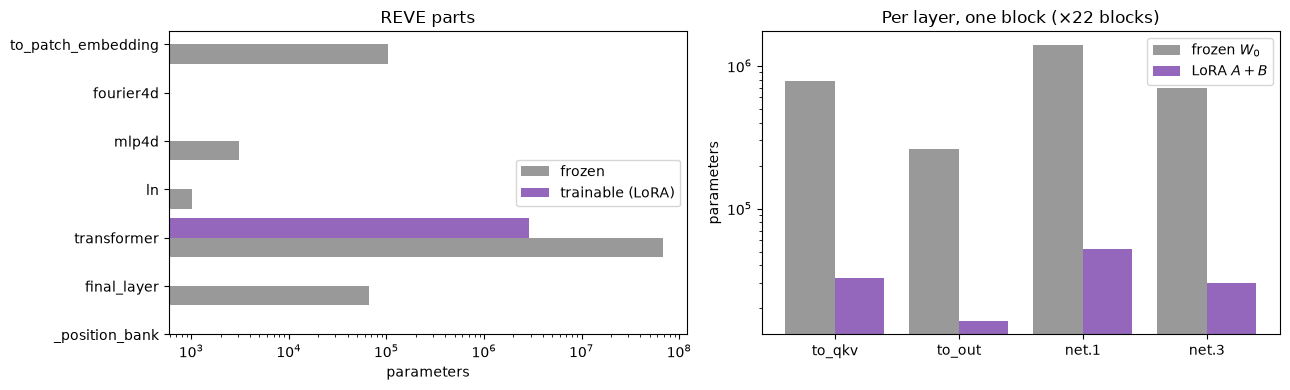

Layer (type:depth-idx)                                            Param #
_ReveWrapper                                                      --
├─REVE: 1-1                                                       --
│    └─Sequential: 2-1                                            --
│    │    └─Linear: 3-1                                           (102,912)
│    └─FourierEmb4D: 2-2                                          --
│    └─Sequential: 2-3                                            --
│    │    └─Linear: 3-2                                           (2,048)
│    │    └─GELU: 3-3                                             --
│    │    └─LayerNorm: 3-4                                        (1,024)
│    └─LayerNorm: 2-4                                             (1,024)
│    └─TransformerBackbone: 2-5                                   --
│    │    └─ModuleList: 3-5                                       71,961,120
│    └─Sequential: 2-6                                            --

In [3]:
visualize_model.show_lora_model(model)
print(summary(model))

In [4]:
print(check_model(model, "eeg", "image"))

    task  n_spatial_locations  n_temporal_samples  \
0  image                    3                 120   
1  image                   19                 120   
2  image                   64                 120   
3  image                  128                 120   

                                              status  
0  forward failed: RuntimeError: maximum size for...  
1  forward failed: RuntimeError: maximum size for...  
2  forward failed: RuntimeError: maximum size for...  
3  forward failed: RuntimeError: maximum size for...  


In [5]:
logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
        handlers=[logging.StreamHandler(), logging.FileHandler("train_log.txt", mode="w")],
    )
logging.captureWarnings(True)
 

In [6]:
overrides = {
        "data.study.source.path": "/egr/research-slim/shared/neuralbench",  # parent of Xu2025Alljoined
        "data.neuro.frequency": 200.0,                    # REVE patch_size = 200 samples
        "data.channel_positions.normalize": False,        # REVE expects raw coordinates
        "lightning_optimizer_config.optimizer.lr": 1e-4,
        "trainer_config.monitor": "val/batch_top5_acc",   # checkpoint on the competition metric
        "delete_checkpoints_on_exit": False,              # keep best.ckpt (remove this line if rejected)
    }

In [7]:
scores = evaluate_model(
        model=model,            # REVE + LoRA backbone
        device="eeg",           # signal type (not the GPU)
        task="image",           # NeuralBench task: EEG-to-image retrieval
        name="reve-lora-r16",
        dataset="xu2025alljoined",
        downstream_wrapper="finetune_mean",
        overrides=overrides,
        download=False,
        prepare=False,      # caches are already warm; set True if you change frequency/dataset
        debug=True,         # set False for the real run
    )

2026-11-14 21:03:40,303 | INFO | neuralbench.evaluate | Serialized model to /egr/research-slim/luozishe/neuralbench/cache/external_models/a8bb4ae3c7f3b0bdb346f4b995250b2e552cccfcf28e2487f7d9777ab4668665.pt
2026-11-14 21:03:40,575 | INFO | neuralbench.experiment_config | --- RUNNING IN DEBUG MODE ---
2026-11-14 21:03:40,884 | WARNING | py.warnings | /egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/neuralset/utils.py:86: UserWarning: The effect of "imsize"=518 might be cancelled by the HuggingFace processor.
  warnings.warn(message)

Seed set to 33
2026-11-14 21:03:41,069 | INFO | neuralbench.main | UID folder: /egr/research-slim/luozishe/neuralbench/save/neuralbench.main.Experiment.run,1/seed=33,task_name=image,brain_model_output_size=1536,delete_checkpoints_on_exit=False,downstream_model_wrapper.aggregation=mean,...925-cf429e34
2026-11-14 21:03:44,592 | INFO | neuralbench.data | Dataset summary:
                              index  subject  filepath 

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Validate metric         ┃          DataLoader 0          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│  val/batch_inv_norm_rank_mean  │       0.4642857015132904       │
│ val/batch_inv_norm_rank_median │       0.4285714030265808       │
│     val/batch_pearson_corr     │     -0.008350343443453312      │
│       val/batch_top5_acc       │       0.5250000357627869       │
│            val/loss            │        2.76501202583313        │
└────────────────────────────────┴────────────────────────────────┘

2026-11-14 21:04:51,475 | WARNING | py.warnings | /egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /egr/research-slim/luozishe/neuralbench/save/neuralbench.main.Experiment.run,1/seed=33,task_name=image,brain_model_output_size=1536,delete_checkpoints_on_exit=False,downstream_model_wrapper.aggregation=mean,...925-cf429e34 exists and is not empty.

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5,6,7]
2026-11-14 21:04:51,852 | WARNING | py.warnings | /egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=127` in the `DataLoader` to improve performance.

2026-11-14 21:04:51,866 | WARNING | py.warnings | /egr/research-slim/luozishe/miniconda

2026-11-14 21:05:01,502 | INFO | neuralbench.main | Best epoch: 0
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
Restoring states from the checkpoint path at /egr/research-slim/luozishe/neuralbench/save/neuralbench.main.Experiment.run,1/seed=33,task_name=image,brain_model_output_size=1536,delete_checkpoints_on_exit=False,downstream_model_wrapper.aggregation=mean,...925-cf429e34/best.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3,4,5,6,7]
Loaded model weights from the checkpoint at /egr/research-slim/luozishe/neuralbench/s

Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full test set retrieval metrics:   0%|          | 0/10 [00:00<?, ?it/s]
Evaluating full 

2026-11-14 21:11:25 - WARNING - exca.task:79 - Computation failed for neuralbench.main.Experiment.run with traceback:
Traceback (most recent call last):
  File "/egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/IPython/core/formatters.py", line 278, in wrapper
    r = method(self, *args, **kwargs)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/IPython/core/formatters.py", line 974, in __call__
    printer = self.lookup(obj)
              ^^^^^^^^^^^^^^^^
  File "/egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/IPython/core/formatters.py", line 455, in lookup
    return self.lookup_by_type(_get_type(obj))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/egr/research-slim/luozishe/miniconda3/envs/neuralbench/lib/python3.12/site-packages/IPython/core/formatters.py", line 485, in lookup_by_type
    if cls in self.type_printers or 

RecursionError: maximum recursion depth exceeded

In [ ]:
if not scores.empty:
        LOGGER.info("Results:\n%s", scores.T.to_string())
        scores.to_csv("scores_reve_lora_r16.csv", index=False)
        LOGGER.info("Saved scores_reve_lora_r16.csv")

In [7]:
ckpts = sorted(glob.glob("/egr/research-slim/luozishe/neuralbench/save/*/*/best.ckpt"), key=os.path.getmtime)
path = ckpts[-1]; print(path)

sd = torch.load(path, map_location="cpu", weights_only=False)["state_dict"]
print(len(sd), "tensors")
for k in list(sd)[:5]: print(k, tuple(sd[k].shape))

/egr/research-slim/luozishe/neuralbench/save/neuralbench.main.Experiment.run,1/seed=33,task_name=image,brain_model_output_size=1536,delete_checkpoints_on_exit=False,downstream_model_wrapper.aggregation=mean,...925-ea125171/best.ckpt
322 tensors
model.wrapped_model.model.to_patch_embedding.0.weight (512, 200)
model.wrapped_model.model.to_patch_embedding.0.bias (512,)
model.wrapped_model.model.mlp4d.0.weight (512, 4)
model.wrapped_model.model.mlp4d.2.weight (512,)
model.wrapped_model.model.mlp4d.2.bias (512,)


In [9]:
lora = {k: v for k, v in sd.items() if "lora_" in k}
head = {k: v for k, v in sd.items() if "lora_" not in k and v.shape[:1] == (1536,)}
B    = [v for k, v in lora.items() if "lora_B" in k]

print(len(lora), "LoRA tensors (expect 176)")
print("head:", {k: tuple(v.shape) for k, v in head.items()})
print("B still all zero:", all((b == 0).all().item() for b in B))         # want False
print("mean |B|:", torch.stack([b.abs().mean() for b in B]).mean().item())

torch.save({"lora": lora, "head": head}, "reve_lora_r16_debug.pt")

lora = {k: v for k, v in sd.items() if "lora_" in k}
head = {k: v for k, v in sd.items() if k.startswith("model.probe.")}
print(len(lora), "LoRA tensors;", {k: tuple(v.shape) for k, v in head.items()})
torch.save({"lora": lora, "head": head}, "reve_lora_r16_debug.pt")

176 LoRA tensors (expect 176)
head: {'model.wrapped_model.model.transformer.layers.0.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.1.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.2.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.3.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.4.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.5.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.6.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.7.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.8.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.9.0.to_qkv.base_layer.weight': (1536, 512), 'model.wrapped_model.model.transformer.layers.10.0.to_qkv.base_